# F3: lattice-image (R) resolution (upcoming)

**Finding** (`notes/theory_audit.md`, F3): crawfish sums $\mathrm{Re}[T^*_u T_v]$ over k with no Bloch phase,
which gives the R = 0 element. "Atom A – atom B" therefore means the copy of B in A's cell, which depends on how
the input wrapped the atoms.

N2 is an isolated molecule with both atoms in one cell, so it can't show this. This notebook uses a 1D dimerized
chain (SSH model) built from crawfish's own weight kernel, `_get_gen_tj_coef_tuv` (R=0, as `state_sep=False` uses). It compares two descriptions
of the *same* crystal that differ only in which copy of B is placed in the cell.

**Target:** $M_t \to M(R)\,e^{2\pi i k_t\cdot R}$ (notes section 2.3), with R the minimum image by default.

**After the fix:** crawfish needs either a synthetic-data path (`ElecData.as_empty` is currently broken) or a
periodic JDFTx fixture to run the "fixed" side here. The last cell says which is missing.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixcompare import *
from crawfish.funcs.general import SIGMA_DEFAULT
from crawfish.core.operations.matrix import _get_gen_tj_coef_tuv

F3_DONE = fix_available("F3")
nk = 60
ks = np.arange(nk) / nk
wk = np.full(nk, 2.0 / nk, dtype=np.float32)  # spin-unpolarized JDFTx convention: weights sum to 2
T_SHORT, T_LONG = -1.0, -0.3                  # hoppings (Ha) for the 0.2 and 0.8 bonds
occ = np.zeros((nk, 2))
occ[:, 0] = 1.0                               # half filling: lower band full


def chain(tau_B):
    """Projections (orthonormal TB orbitals: T = eigenvectors) and eigenvalues; B images at tau_B + R."""
    proj = np.zeros((nk, 2, 2), dtype=np.complex64)
    e = np.zeros((nk, 2))
    for i, k in enumerate(ks):
        hab = sum(t * np.exp(2j * np.pi * k * R) for R in range(-2, 3)
                  for d, t in [(0.2, T_SHORT), (0.8, T_LONG)] if np.isclose(abs(tau_B + R), d))
        ev, C = np.linalg.eigh(np.array([[0, hab], [np.conj(hab), 0]]))
        e[i], proj[i] = ev, C.T  # proj[t, j, u] = C_uj
    return proj, e


def hopping(tau_B, R):
    d = abs(tau_B + R)
    return T_SHORT if np.isclose(d, 0.2) else T_LONG if np.isclose(d, 0.8) else 0.0


def resolved_weights(proj, tau_B, R, mode):
    """Reference: w_k Re[conj(C_A) M(R) e^{2 pi i k R} C_B] with M = 1 (bond order) or the hopping (COHP)."""
    m = 1.0 if mode == "como" else hopping(tau_B, R)
    ph = np.exp(2j * np.pi * ks * R)[:, None]
    return wk[:, None] * (np.conj(proj[:, :, 0]) * m * ph * proj[:, :, 1]).real


WRAPPINGS = {"B at +0.2": 0.2, "B at -0.8": -0.8}
data = {name: chain(tau) for name, tau in WRAPPINGS.items()}
ones = np.ones((1, 2, 2), dtype=np.complex64)
m_t = np.zeros(nk, dtype=np.int64)
crawfish_r0 = lambda proj: _get_gen_tj_coef_tuv(proj, ones, m_t, wk, [0], [1])  # crawfish's pCOMO kernel (R=0)

## Integrated bond order: crawfish (R = 0 only) vs. R-resolved

Each panel is one description of the same crystal. The bars are R-resolved bond orders, labelled by bond length,
and the red line is what crawfish reports for "A–B" today.

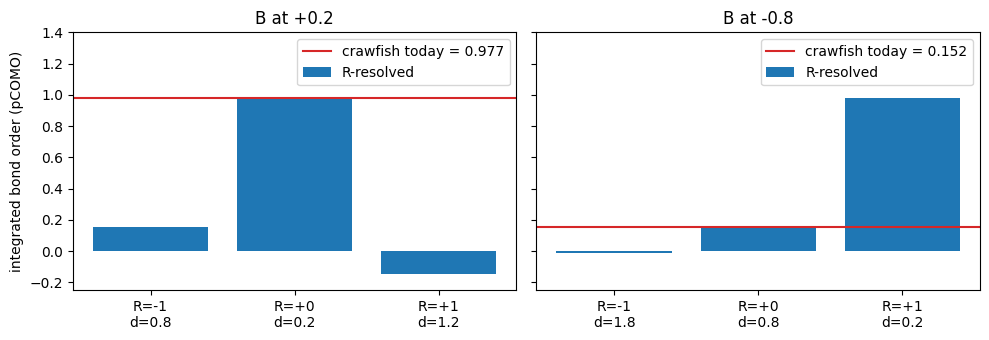

,crawfish (R=0),nearest image R,"R-resolved, nearest image"
cell choice,,,
B at +0.2,0.9771,0,0.9771
B at -0.8,0.1517,1,0.9771


In [2]:
rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (name, tau) in zip(axes, WRAPPINGS.items()):
    proj, e = data[name]
    crawfish_val = float(np.sum(crawfish_r0(proj) * occ))
    vals = {R: float(np.sum(resolved_weights(proj, tau, R, "como") * occ)) for R in (-1, 0, 1)}
    ax.bar([f"R={R:+d}\nd={abs(tau + R):.1f}" for R in vals], list(vals.values()), color="C0", label="R-resolved")
    ax.axhline(crawfish_val, color="C3", label=f"crawfish today = {crawfish_val:.3f}")
    ax.set_title(name)
    ax.set_ylim(-0.25, 1.4)
    ax.legend(loc="upper right")
    nearest = min(vals, key=lambda R: abs(tau + R))
    rows.append({"cell choice": name, "crawfish (R=0)": crawfish_val, "nearest image R": nearest,
                 "R-resolved, nearest image": vals[nearest]})
axes[0].set_ylabel("integrated bond order (pCOMO)")
fig.tight_layout()
savefig(fig, "F3_bond_orders")
plt.show()
table = pd.DataFrame(rows).set_index("cell choice")
table.round(4)

## Energy-resolved −COHP of "the A–B bond"

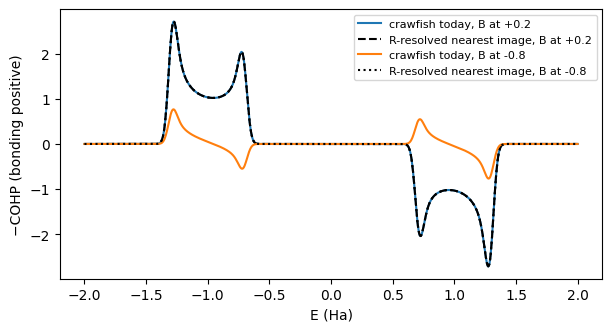

In [3]:
erange = np.linspace(-2.0, 2.0, 801)
gauss = lambda e0: np.exp(-((erange[:, None, None] - e0[None]) ** 2) / 0.002) / np.sqrt(np.pi * 0.002)
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, (name, tau) in enumerate(WRAPPINGS.items()):
    proj, e = data[name]
    # Today: crawfish R=0 weights times the R=0 hopping of that cell choice
    w_now = crawfish_r0(proj) * hopping(tau, 0)
    ax.plot(erange, -(gauss(e) * w_now[None]).sum(axis=(1, 2)), color=f"C{i}", label=f"crawfish today, {name}")
    R = min((-1, 0, 1), key=lambda R: abs(tau + R))
    w_ref = resolved_weights(proj, tau, R, "cohp")
    ax.plot(erange, -(gauss(e) * w_ref[None]).sum(axis=(1, 2)), "k--" if i == 0 else "k:", lw=1.5,
            label=f"R-resolved nearest image, {name}")
ax.set_xlabel("E (Ha)")
ax.set_ylabel("−COHP (bonding positive)")
ax.legend(fontsize=8)
savefig(fig, "F3_cohp_spectra")
plt.show()

## Tests

In [4]:
# The R-resolved nearest-image result doesn't depend on the cell choice
assert np.isclose(table["R-resolved, nearest image"].iloc[0], table["R-resolved, nearest image"].iloc[1], atol=1e-6)

if not F3_DONE:
    # Known-bug check: crawfish's A-B value depends on the cell choice. Remove once F3 lands.
    assert not np.isclose(table["crawfish (R=0)"].iloc[0], table["crawfish (R=0)"].iloc[1], atol=1e-3)
    print("F3 not implemented yet: crawfish's A-B bond order depends on the cell choice "
          f"({table['crawfish (R=0)'].iloc[0]:.4f} vs {table['crawfish (R=0)'].iloc[1]:.4f}).")
else:
    print("F3 is implemented. Add the crawfish R-resolved calls for this chain here (needs a working synthetic "
          "ElecData path or a periodic JDFTx fixture) and assert they match the reference.")
print("All F3 checks passed.")

F3 not implemented yet: crawfish's A-B bond order depends on the cell choice (0.9771 vs 0.1517).
All F3 checks passed.
